# 03 · Marketing bancario: análisis de conversión y caché con Redis

Dataset **UCI Bank Marketing** (Moro, Rita y Cortez; licencia CC BY 4.0): 45.211 contactos telefónicos de un banco portugués (mayo 2008 – noviembre 2010) para ofrecer un depósito a plazo. Lo carga el pipeline ETL en `marketing.contactos`.

**Pregunta:** ¿qué perfiles y circunstancias se asocian a una mayor tasa de suscripción?

**Antes de empezar**, carga los datos (una vez):
```bash
docker compose run --rm etl
```

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from src.cache import QueryCache, benchmark
from src.config import get_engine, get_redis
from src.queries import get_query

pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})

engine = get_engine()
cache = QueryCache(get_redis())      # las consultas pasan por Redis (TTL por defecto: 300 s)
cache.invalidate()                   # partimos de una caché vacía para que los tiempos sean comparables

def consulta(nombre, **params):
    return cache.read_sql(engine, get_query(nombre), params)

resumen = consulta("marketing_resumen")
assert resumen.loc[0, "contactos"] > 0, "marketing.contactos está vacía: ejecuta el ETL (ver arriba)"
resumen.T

,0
contactos,45211
suscritos,5289
tasa_conversion_pct,11.7
primer_contacto,2008-05-05 00:00:00
ultimo_contacto,2010-11-17 00:00:00


## 1. Visión global

In [2]:
tasa_global = resumen.loc[0, "tasa_conversion_pct"]
print(f"{resumen.loc[0, 'suscritos']:,} suscripciones sobre {resumen.loc[0, 'contactos']:,} contactos → {tasa_global:.2f} %")

5,289 suscripciones sobre 45,211 contactos → 11.70 %


## 2. Conversión por profesión

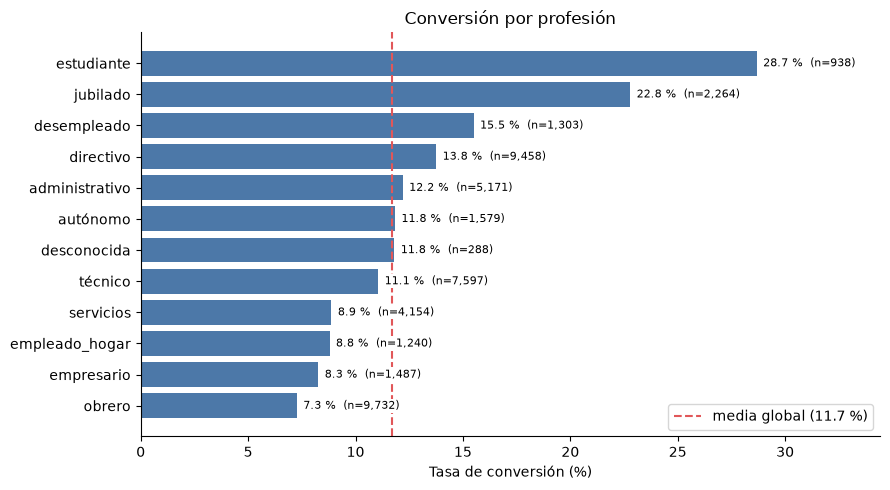

In [3]:
prof = consulta("marketing_conversion_por_profesion").sort_values("tasa_conversion_pct")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(prof["profesion"], prof["tasa_conversion_pct"], color="#4C78A8")
ax.axvline(tasa_global, color="#E15759", ls="--", label=f"media global ({tasa_global:.1f} %)")
for y, (t, n) in enumerate(zip(prof["tasa_conversion_pct"], prof["contactos"])):
    ax.text(t + 0.3, y, f"{t:.1f} %  (n={n:,})", va="center", fontsize=8,
            bbox=dict(facecolor="white", edgecolor="none", pad=1), zorder=3)
ax.set_xlabel("Tasa de conversión (%)")
ax.set_title("Conversión por profesión")
ax.legend(loc="lower right")
ax.margins(x=0.2)
plt.tight_layout()

## 3. Efecto de la campaña anterior y de la edad

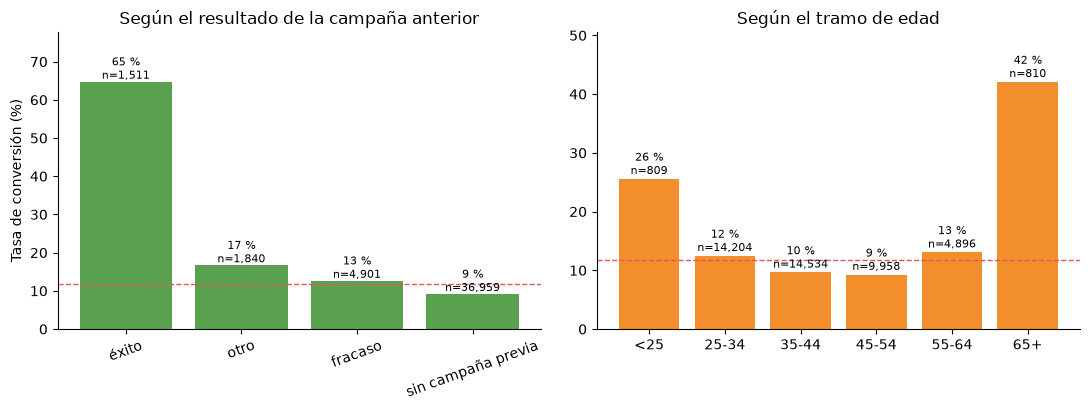

In [4]:
prev = consulta("marketing_conversion_por_resultado_previo")
edad = consulta("marketing_conversion_por_edad")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].bar(prev["resultado_previo"], prev["tasa_conversion_pct"], color="#59A14F")
axes[0].set_title("Según el resultado de la campaña anterior")
axes[0].set_ylabel("Tasa de conversión (%)")
axes[0].tick_params(axis="x", rotation=20)
axes[1].bar(edad["tramo_edad"], edad["tasa_conversion_pct"], color="#F28E2B")
axes[1].set_title("Según el tramo de edad")
for ax, df, col in ((axes[0], prev, "resultado_previo"), (axes[1], edad, "tramo_edad")):
    for x, (t, n) in enumerate(zip(df["tasa_conversion_pct"], df["contactos"])):
        ax.text(x, t + 0.8, f"{t:.0f} %\nn={n:,}", ha="center", fontsize=8)
    ax.axhline(tasa_global, color="#E15759", ls="--", lw=1)
    ax.margins(y=0.2)
plt.tight_layout()

## 4. Evolución en el tiempo

El CSV solo trae día y mes; el ETL deduce el año porque `bank-full.csv` está ordenado por fecha (ver `src/etl/transform.py`).

,mes,contactos,tasa_conversion_pct
0,2008-05-01,7957,3.24
2,2008-07-01,6380,6.02
11,2009-05-01,5575,9.56


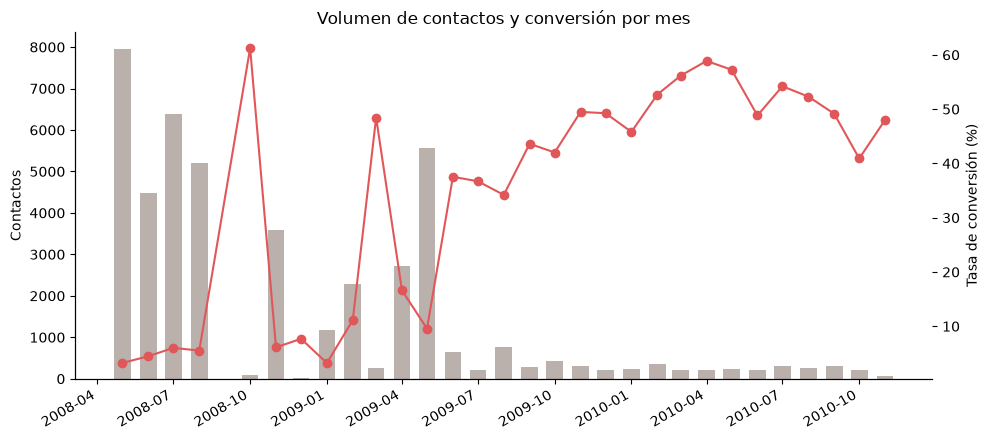

In [5]:
mensual = consulta("marketing_conversion_mensual")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(mensual["mes"], mensual["contactos"], width=20, color="#BAB0AC", label="Contactos (eje izq.)")
ax.set_ylabel("Contactos")
ax2 = ax.twinx()
ax2.plot(mensual["mes"], mensual["tasa_conversion_pct"], color="#E15759", marker="o", label="Conversión % (eje der.)")
ax2.set_ylabel("Tasa de conversión (%)")
ax.set_title("Volumen de contactos y conversión por mes")
fig.autofmt_xdate()
plt.tight_layout()
mensual.sort_values("contactos", ascending=False).head(3)

## 5. Duración de la llamada

In [6]:
dur = consulta("marketing_duracion_percentiles")
dur["suscrito"] = dur["suscrito"].map({True: "Suscribe", False: "No suscribe"})
dur

,suscrito,contactos,p25_seg,mediana_seg,p75_seg
0,No suscribe,39922,95.0,164.0,279.0
1,Suscribe,5289,244.0,426.0,725.0


## 6. Redis como caché de consultas: ¿cuánto se gana?

`benchmark()` mide, para cada consulta, la media de varias ejecuciones **directas en PostgreSQL**, la primera lectura con caché vacía (consulta + escritura en Redis) y la media de lecturas **ya cacheadas**.

In [7]:
consultas = ["marketing_resumen", "marketing_duracion_percentiles", "marketing_conversion_cubo"]
filas = []
for nombre in consultas:
    r = benchmark(cache, engine, get_query(nombre), repeats=20)
    filas.append({"consulta": nombre, **r})
tiempos = pd.DataFrame(filas).set_index("consulta").round(2)
tiempos.columns = ["PostgreSQL (ms)", "1ª lectura (ms)", "Redis (ms)", "aceleración (x)"]
tiempos

,PostgreSQL (ms),1ª lectura (ms),Redis (ms),aceleración (x)
consulta,,,,
marketing_resumen,13.75,19.32,4.95,2.78
marketing_duracion_percentiles,23.24,26.52,3.34,6.95
marketing_conversion_cubo,73.18,65.38,4.34,16.85


Estadísticas de la caché en esta sesión: CacheStats(hits=60, misses=9, errors=0)


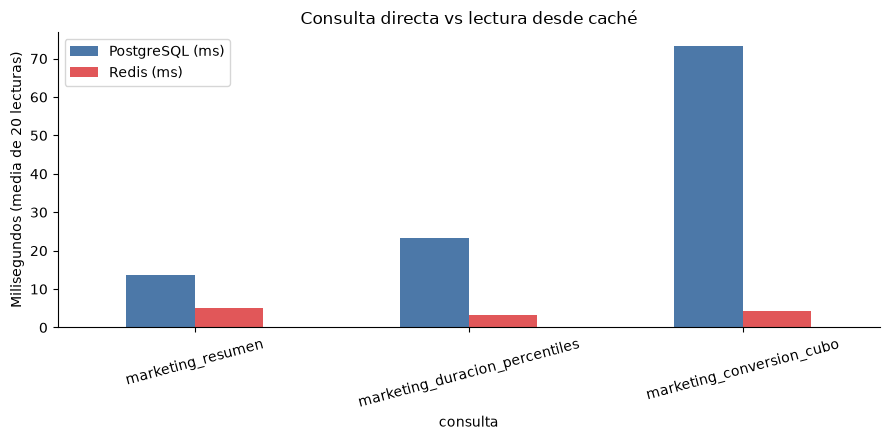

In [8]:
ax = tiempos[["PostgreSQL (ms)", "Redis (ms)"]].plot.bar(color=["#4C78A8", "#E15759"], rot=15)
ax.set_ylabel("Milisegundos (media de 20 lecturas)")
ax.set_title("Consulta directa vs lectura desde caché")
plt.tight_layout()
print(f"Estadísticas de la caché en esta sesión: {cache.stats}")

## Conclusiones

**Sobre los datos** (tasa global: 11,70 %):

- **El historial pesa más que el perfil.** Los clientes con una campaña anterior exitosa suscriben el 64,7 %, frente al 9,2 % de quienes no tenían campaña previa. Hay solo 1.511 de los primeros, pero es la señal más fuerte.
- **Profesión y edad.** Estudiantes (28,7 %) y jubilados (22,8 %) convierten muy por encima de la media; obreros (7,3 %) y empresarios (8,3 %), por debajo. Por edad destacan los menores de 25 (25,6 %) y los mayores de 65 (42,1 %), aunque esos tramos tienen solo ~800 contactos cada uno.
- **Cuidado con los meses con conversión alta.** Los porcentajes más altos (p. ej. 61 % en octubre de 2008) corresponden a meses con muy pocos contactos (80 en ese caso), mientras que los meses de mucho volumen convierten poco (mayo de 2008: 7.957 contactos, 3,2 %). Puede reflejar un cambio de estrategia de selección de clientes y no estacionalidad: con estos datos no se puede distinguir.
- **La duración no es una variable "accionable".** Quien suscribe habla de mediana 426 s frente a 164 s, pero la duración solo se conoce *después* de llamar; sirve para describir, no para decidir a quién llamar.
- **Son asociaciones, no causas:** el dataset es observacional y la selección de a quién se llamó no fue aleatoria.

**Sobre la caché:** la tabla de la sección 6 muestra el tiempo de cada consulta con y sin Redis en *tu* máquina. Con un dataset de 45 mil filas y consultas de milisegundos, la ganancia absoluta es pequeña; la caché compensa sobre todo en consultas pesadas (`marketing_conversion_cubo`), con muchos usuarios repitiendo la misma consulta o con bases de datos mucho mayores. Tras cada carga del ETL la caché se invalida automáticamente para no servir datos obsoletos.

*Fuente de los datos: S. Moro, R. Laureano y P. Cortez (2011), "Using Data Mining for Bank Direct Marketing: An Application of the CRISP-DM Methodology"; UCI Machine Learning Repository, CC BY 4.0.*